In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import os
import time
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from keras.models import Sequential
from keras.layers import Input, Dense, Conv2D, MaxPooling2D, Dropout, Flatten
from keras import callbacks, regularizers
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sn



In [2]:
path_train = "../Data/dataset_yawn_eye/train"
path_test = "../Data/dataset_yawn_eye/test/"
path_haar_faces = "../Data/dataset_yawn_eye/haarcascade/haarcascade_frontalface_default.xml"

IMG_SIZE = (145, 145)

labels = os.listdir(path_train)
labels.remove(".DS_Store")
labels.remove("Open")
labels.remove("Closed")


labels

['no_yawn', 'yawn']

### Read preprocessed CSV-data

In [3]:

def read_all_csv_data():
    path_x_csv = "../Data/dataset_yawn_eye/preprocessed/x_train_face.csv"
    path_y_csv = "../Data/dataset_yawn_eye/preprocessed/y_train_face.csv"
    path_x_csv_test = "../Data/dataset_yawn_eye/preprocessed/x_test_face.csv"
    path_y_csv_test = "../Data/dataset_yawn_eye/preprocessed/y_test_face.csv"

    x_read = pd.read_csv(path_x_csv, index_col = 0)
    y_read = pd.read_csv(path_y_csv, index_col = 0)
    x_read_test = pd.read_csv(path_x_csv_test, index_col = 0)
    y_read_test = pd.read_csv(path_y_csv_test, index_col = 0)

    x_train = x_read.values.reshape((len(x_read.index), IMG_SIZE[0], IMG_SIZE[1]))
    y_train = np.array(y_read).reshape(np.array(y_read).shape[0]).tolist()

    x_test = x_read.values.reshape((len(x_read.index), IMG_SIZE[0], IMG_SIZE[1]))
    y_test = np.array(y_read).reshape(np.array(y_read).shape[0]).tolist()

    del x_read
    del y_read
    del x_read_test
    del y_read_test

    return x_train, x_test, y_train, y_test


### Create and train simple MLP model

# CNN

In [4]:
x_train_cnn, x_test_cnn, y_train_cnn, y_test_cnn = read_all_csv_data()

# normalize data
x_train_cnn = x_train_cnn.astype(float) / 255
x_train_cnn = x_train_cnn.reshape((x_train_cnn.shape[0], x_train_cnn.shape[1], x_train_cnn.shape[2], 1))
x_test_cnn = x_test_cnn.astype(float) / 255
x_test_cnn = x_test_cnn.reshape((x_test_cnn.shape[0], x_test_cnn.shape[1], x_test_cnn.shape[2], 1))

encoder_cnn = LabelEncoder()
y_train_cnn = encoder_cnn.fit_transform(y_train_cnn)
y_test_cnn = encoder_cnn.fit_transform(y_test_cnn)

### Create CNN architecture + train model

In [7]:
model_cnn = Sequential()
model_cnn.add(Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 1)))
model_cnn.add(Conv2D(128, (3, 3), activation="relu"))
model_cnn.add(MaxPooling2D(2, 2))
model_cnn.add(Conv2D(64, (3, 3), activation="relu"))
model_cnn.add(MaxPooling2D(2, 2))
model_cnn.add(Conv2D(32, (3, 3), activation="relu"))
model_cnn.add(MaxPooling2D(2, 2))
model_cnn.add(Conv2D(16, (3, 3), activation="relu"))
model_cnn.add(MaxPooling2D(2, 2))
model_cnn.add(Flatten())
model_cnn.add(Dropout(0.3))
model_cnn.add(Dense(64, activation="relu", kernel_regularizer=regularizers.L2(1e-4)))
model_cnn.add(Dropout(0.3))
model_cnn.add(Dense(len(set(y_train_cnn)), activation="softmax"))


model_cnn.compile(
    optimizer = "adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False), 
    metrics=[tf.keras.metrics.SparseCategoricalAccuracy()]
)

model_cnn.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_8 (Conv2D)           (None, 143, 143, 128)     1280      
                                                                 
 max_pooling2d_8 (MaxPoolin  (None, 71, 71, 128)       0         
 g2D)                                                            
                                                                 
 conv2d_9 (Conv2D)           (None, 69, 69, 64)        73792     
                                                                 
 max_pooling2d_9 (MaxPoolin  (None, 34, 34, 64)        0         
 g2D)                                                            
                                                                 
 conv2d_10 (Conv2D)          (None, 32, 32, 32)        18464     
                                                                 
 max_pooling2d_10 (MaxPooli  (None, 16, 16, 32)       

In [8]:
# early stopping callback

early_stopping_cnn = callbacks.EarlyStopping(
    monitor = "val_loss",
    mode = "min",
    min_delta = 0.02,
    patience = 5,
    restore_best_weights = True
)

In [9]:
timer_start = time.time()

history_cnn = model_cnn.fit(
    x_train_cnn,
    y_train_cnn,
    validation_data=(x_test_cnn, y_test_cnn), 
    # callbacks=[early_stopping_cnn],
    epochs = 50
)

timer_end = time.time()


print('\nGesamtlaufzeit: {:5.3f}s'.format(timer_end - timer_start))

Epoch 1/50
39/39 [==============================] - 47s 1s/step - loss: 0.7056 - sparse_categorical_accuracy: 0.5285 - val_loss: 0.6999 - val_sparse_categorical_accuracy: 0.5000
Epoch 2/50
39/39 [==============================] - 47s 1s/step - loss: 0.6882 - sparse_categorical_accuracy: 0.5570 - val_loss: 0.6410 - val_sparse_categorical_accuracy: 0.6279
Epoch 3/50
39/39 [==============================] - 49s 1s/step - loss: 0.6346 - sparse_categorical_accuracy: 0.6352 - val_loss: 0.5841 - val_sparse_categorical_accuracy: 0.6824
Epoch 4/50
39/39 [==============================] - 44s 1s/step - loss: 0.5907 - sparse_categorical_accuracy: 0.6726 - val_loss: 0.5339 - val_sparse_categorical_accuracy: 0.7459
Epoch 5/50
39/39 [==============================] - 44s 1s/step - loss: 0.5496 - sparse_categorical_accuracy: 0.7093 - val_loss: 0.5126 - val_sparse_categorical_accuracy: 0.7500
Epoch 6/50
39/39 [==============================] - 44s 1s/step - loss: 0.5502 - sparse_categorical_accuracy: 

In [10]:
# predicts

predictions_cnn = model_cnn.predict(x_test_cnn)
y_pred_cnn = []
for i in predictions_cnn:
    y_pred_cnn.append(np.array(i).argmax())

y_test_cnn_transformed = encoder_cnn.inverse_transform(y_test_cnn)
y_pred_cnn_transformed = encoder_cnn.inverse_transform(y_pred_cnn)

report_cnn = classification_report(y_test_cnn_transformed, y_pred_cnn_transformed)
print(report_cnn)

39/39 [==============================] - 5s 129ms/step
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       615
           1       1.00      0.99      0.99       613

    accuracy                           0.99      1228
   macro avg       0.99      0.99      0.99      1228
weighted avg       0.99      0.99      0.99      1228



In [16]:
# model_cnn.save("../Data/models/cnn_old_face_acc_99.h5")

/Users/simon/envs/datascience/lib/python3.11/site-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [17]:
y_pred_cnn = []
for i in predictions_cnn:
    y_pred_cnn.append(np.array(i).argmax())

y_test_cnn_retransformed = encoder_cnn.inverse_transform(y_test_cnn)
y_pred_cnn_retransformed = encoder_cnn.inverse_transform(y_pred_cnn)

### Evaluation

In [18]:
sorted_labels = sorted(list(set(y_test_cnn_retransformed.tolist())))
matrix_cnn = confusion_matrix(y_test_cnn_transformed, y_pred_cnn_transformed, normalize = "true")

misclassifications = []
for i in range(len(matrix_cnn[0]) - 1):
    for j in range(len(matrix_cnn[0]) - 1):
        if matrix_cnn[i][j] > 0.2 and i != j:
            misclassifications.append((sorted_labels[i], sorted_labels[j], matrix_cnn[i][j]))

for x in misclassifications:
    print(x)

In [19]:
def show_confusion_matrix(y_test, y_pred, path="../imgs/cnn/"):
    """
    prints the normalized confusion matrix in a seaborn heatmap
    """
    matrix = confusion_matrix(y_test, y_pred, normalize='true')
    sortedLabels = sorted(list(set(y_test.tolist())))

    plt.figure(figsize=(7, 7))
    sn.heatmap(matrix, xticklabels=sortedLabels, yticklabels=sortedLabels, annot=True, cmap="coolwarm")

    plt.savefig(os.path.join(path, 'confusion_matrix.svg'))

    plt.show()


def show_epoch_history(history, path="../imgs/cnn/"):
    history_df = pd.DataFrame(history.history)

    plot = history_df.loc[:,['loss', 'val_loss', 'sparse_categorical_accuracy', 'val_sparse_categorical_accuracy']].plot()
    fig = plot.get_figure()

    fig.savefig(os.path.join(path, 'epoch_history.svg'))


def evaluate_neural_network(y_test, y_pred, path="../imgs/cnn/"):
    """
    prints the precision, recall and f1-score of each label in a seaborn bar plot
    """
    report_raw = classification_report(y_test, y_pred, output_dict=True)
    report = []

    for i in sorted(report_raw.keys()):
        if i not in ['accuracy', 'macro avg', 'weighted avg']:
            report.append([report_raw[i]['precision'], 'precision', i])
            report.append([report_raw[i]['f1-score'], 'f1-score', i])
            report.append([report_raw[i]['recall'], 'recall', i])

    report_df = pd.DataFrame(data = report, columns = ['value', 'type', 'class'])

    plt.figure(figsize = (5, 8))
    plt.title("precision, recall and f1-score of each class")
    sn.barplot(data = report_df, y = 'class', x = 'value', hue = 'type')

    plt.savefig(os.path.join(path, 'evaluation.svg'))

    plt.show()



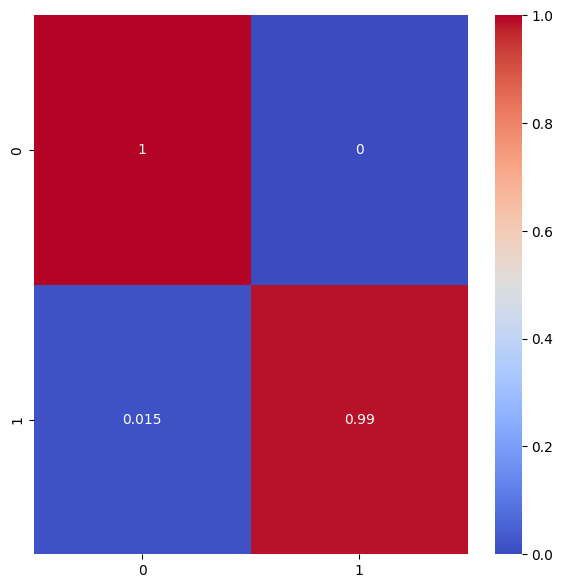

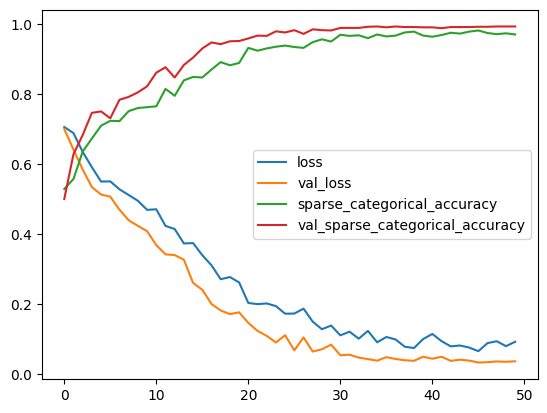

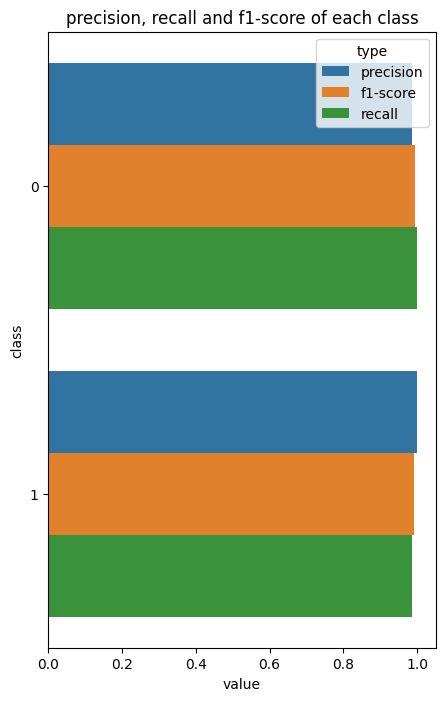

In [20]:
# for cnn
show_confusion_matrix(y_test_cnn, y_pred_cnn, "../imgs/cnn/old_model/")
show_epoch_history(history_cnn, "../imgs/cnn/old_model/")
evaluate_neural_network(y_test_cnn, y_pred_cnn, "../imgs/cnn/old_model/")


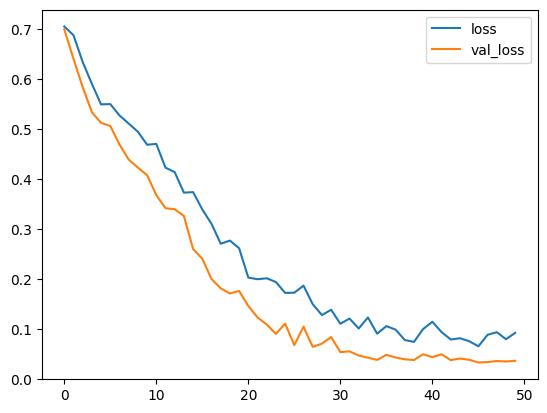

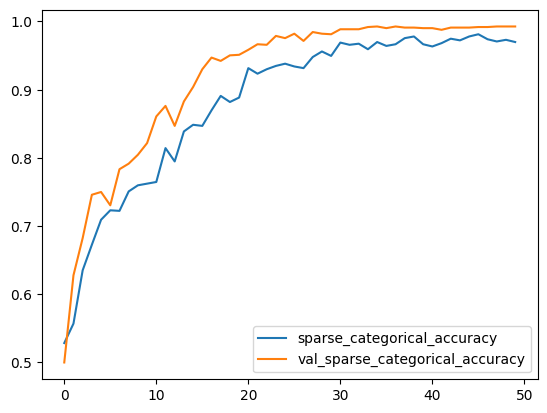

In [21]:


def show_epoch_history_separate(history, path="../imgs/cnn/"):
    history_df = pd.DataFrame(history.history)

    plot = history_df.loc[:, ['loss', 'val_loss']].plot()
    fig1 = plot.get_figure()
    fig1.savefig(os.path.join(path, 'epoch_history_loss.svg'))


    plot2 = history_df.loc[:, ['sparse_categorical_accuracy', 'val_sparse_categorical_accuracy']].plot()
    fig2 = plot2.get_figure()
    fig2.savefig(os.path.join(path, 'epoch_history_accuracy.svg'))


show_epoch_history_separate(history_cnn, "../imgs/cnn/old_model/")
